# 7 · Mercadotecnia digital: la campaña
**Torre del Caribe** · Universidad Nacional Rosario Castellanos · Licenciatura en Ciencia de Datos para Negocios, 5.º
semestre 2026-2 · Equipo 2

| | |
|---|---|
| **Materia (UCA)** | Mercadotecnia Digital |
| **Profesor** | Víctor Hugo Reyes Anselmo |
| **Criterio de la rúbrica** | 7. Mercadotecnia digital (8 %) |
| **Equipo** | Brandon Uriel García Sánchez · Maribel Mondragón Mercado · Jesús Ramírez Isidro · Enrique González Ortega |

La campaña **"El sur tiene espacio"** junta todo lo anterior. El incidente crítico de la materia pide que
"todas las decisiones sobre el buyer persona, los mensajes, los canales y el presupuesto" estén justificadas con las
otras cinco materias, y pregunta qué hacer "si la campaña genera una afluencia mayor a la capacidad del destino".
Seguimos el esquema **STP** (segmentar, elegir y posicionar; Kotler y Keller, 2016) y, en cada rasgo, decimos si es un
**dato**, un **cálculo** (derivado), un **supuesto** o un **hueco**.

| Parte | Qué respondemos |
|---|---|
| 1. Segmentar | ¿Quién visita el sur y quién llega al estado? |
| 2. Elegir: buyer persona | ¿A quién le habla la campaña? |
| 3. Posicionar: la marca | ¿Qué promete y cómo se ve? |
| 4. Los mensajes | Cada promesa con su dato |
| 5. Los medios y el embudo | ¿Dónde se anuncia y qué se espera de cada peso? |
| 6. Indicadores | ¿Cómo se sabe si funciona? |
| 7. La regla anti-colapso | ¿Qué pasa si llega más gente de la que cabe? |
| 8. La integración | Cómo cada materia alimenta a la siguiente |

**Cómo leer este notebook.** Antes de cada celda de código explicamos qué hacemos y por qué; dentro del código, cada
renglón lleva su comentario. Al terminar cada paso comparamos nuestro resultado con el que guardó el proyecto (función
`coincide`): si una cifra no coincidiera, el notebook se detendría ahí. El documento técnico del equipo
(*Torre_del_Caribe.pdf*) tiene las fórmulas con su ejemplo resuelto a mano.

**Cómo correrlo.** Python 3.11 con `pip install -r requirements.txt` desde la carpeta de la entrega; abrir en Jupyter o
VS Code y elegir *Ejecutar todo*. Ya viene ejecutado, así que también se puede leer sin correrlo.

In [1]:
%matplotlib inline
# Preparación. Buscamos la carpeta de la entrega (la que tiene datos/silver), cargamos las librerías,
# definimos el estilo de las gráficas y la función que compara nuestras cifras con las del proyecto.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings("ignore")                        # avisos de versiones de librerías que no cambian resultados
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "silver").is_dir())
SILVER, GOLD = RAIZ / "datos" / "silver", RAIZ / "datos" / "gold"   # datos limpios y resultados del proyecto
FIGURAS = Path.cwd() / "figuras"                          # aquí guardamos cada gráfica como PNG
FIGURAS.mkdir(exist_ok=True)

# Colores institucionales de la UNRC (guinda y dorado) y una paleta para varias series.
GUINDA, DORADO, GRIS = "#9F2241", "#BC955C", "#3A3A3A"
PALETA = ["#9F2241", "#BC955C", "#565393", "#58A65D", "#8CAFDD", "#F26E50", "#465973"]
for f in (RAIZ / "herramientas" / "fuentes").glob("NotoSans-*.ttf"):
    font_manager.fontManager.addfont(str(f))          # la letra Noto Sans viene en la entrega
plt.rcParams.update({"font.family": "Noto Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": GUINDA, "axes.titlesize": 12,
                     "text.color": GRIS, "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
                     "figure.facecolor": "white", "savefig.dpi": 160, "savefig.bbox": "tight"})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def coincide(nombre, nuestro, proyecto, tolerancia=1e-6):
    """Compara un resultado de este notebook con el que guardó el proyecto. Si no coincide, se detiene."""
    a = np.asarray(nuestro, dtype=float).ravel()
    b = np.asarray(proyecto, dtype=float).ravel()
    assert a.shape == b.shape, f"{nombre}: tamaños distintos {a.shape} y {b.shape}"
    dif = float(np.nanmax(np.abs(a - b))) if len(a) else 0.0
    print(f"{'✓' if dif <= tolerancia else '✗'} {nombre}: coincide con el proyecto (diferencia máxima {dif:.2g})")
    assert dif <= tolerancia, f"{nombre} no coincide con el proyecto"


def guardar(fig, nombre):
    """Guarda la gráfica en figuras/ con un nombre claro."""
    fig.savefig(FIGURAS / f"{nombre}.png")


print("Carpeta de la entrega:", RAIZ)

Carpeta de la entrega: C:\Users\Uriel\Desktop\PP 5to semestre CASCO SANTO TOMAS\Entregable


## 1. Segmentar: lo que dicen los datos
Tres fuentes oficiales: el INAH (quién visita las zonas del sur, nacional o extranjero), la Unidad de Política
Migratoria vía DataTur (qué extranjeros llegan por avión, de qué país, en qué mes) y la ENDUTIH 2025 del INEGI (cómo se
informa la gente).

In [2]:
import json
campana = json.loads((GOLD / "campana.json").read_text(encoding="utf-8"))

i = pd.read_parquet(SILVER / "inah")
q = i[i.es_qroo & (i.anio.astype(int) == 2025)]
v = q.groupby("region_campana").visitantes.sum()                             # visitantes 2025 por región
nac = q[q.papel_campana == "promovida"].groupby(["region_campana", "tipo_visitante"]).visitantes.sum().unstack()
n = pd.read_parquet(SILVER / "nacionalidad")
c = n[(n.lugar_campana == "Cancún") & (n.anio.astype(int) == 2025)]          # extranjeros que llegaron a Cancún
tot = c.llegadas_extranjeros.sum()
pais = c.groupby("pais").llegadas_extranjeros.sum() / tot * 100
mes = c.groupby("mes").llegadas_extranjeros.sum()
k = {"tulum": int(v["Tulum"]), "ruta": int(v["Ruta arqueológica del sur"]), "bahia": int(v["Bahía Calderitas–Oxtankah"]),
     "veces_ruta": round(v["Tulum"] / v["Ruta arqueológica del sur"], 1),
     "pct_nac_bahia": round(nac.loc["Bahía Calderitas–Oxtankah", "nacional"] / nac.loc["Bahía Calderitas–Oxtankah"].sum() * 100, 1),
     "pct_nac_ruta": round(nac.loc["Ruta arqueológica del sur", "nacional"] / nac.loc["Ruta arqueológica del sur"].sum() * 100, 1),
     "cancun_extranjeros": int(tot),
     "chetumal_extranjeros": int(n[(n.lugar_campana == "Chetumal") & (n.anio.astype(int) == 2025)].llegadas_extranjeros.sum()),
     "pct_eeuu": round(pais["Estados Unidos"], 1), "pct_canada": round(pais["Canadá"], 1),
     "pct_mujeres": round(c[c.sexo == "mujer"].llegadas_extranjeros.sum() / tot * 100, 1),
     "mes_pico": int(mes.idxmax()), "mes_bajo": int(mes.idxmin())}
coincide("cifras de la campaña", [k[x] for x in k], [campana["cifras"][x] for x in k])
pd.Series(k).rename("valor").to_frame()

✓ cifras de la campaña: coincide con el proyecto (diferencia máxima 0)


,valor
tulum,1031443.0
ruta,66628.0
bahia,11017.0
veces_ruta,15.5
pct_nac_bahia,94.8
pct_nac_ruta,63.3
cancun_extranjeros,9408423.0
chetumal_extranjeros,250.0
pct_eeuu,56.3
pct_canada,17.1


**Lo que dicen.**
- **Quién visita el sur:** Oxtankah recibe 94.8 % de mexicanos; la Ruta, 63.3 % de mexicanos y 36.7 % de extranjeros.
- **Quién llega al estado:** 9.4 millones de extranjeros llegaron a Cancún en 2025; 56.3 % de Estados Unidos y 17.1 %
  de Canadá; 53.4 % mujeres; más en marzo y menos en septiembre.
- **El hallazgo que define todo:** al aeropuerto de Chetumal llegaron **250** extranjeros en 2025. El extranjero no llega
  al sur por avión: entra por Cancún y baja por carretera, en Tren Maya, desde Belice o en crucero.
- **Cómo se informan (ENDUTIH 2025):** 92.1 % de la población de Quintana Roo usa internet; de quienes tienen teléfono
  inteligente, 90.6 % usa mensajería y 80.4 % redes sociales.
- **Qué valoran (notebook 3):** el ruido, la suciedad, el precio y las multitudes hunden una reseña; la calma y la
  cultura la protegen.

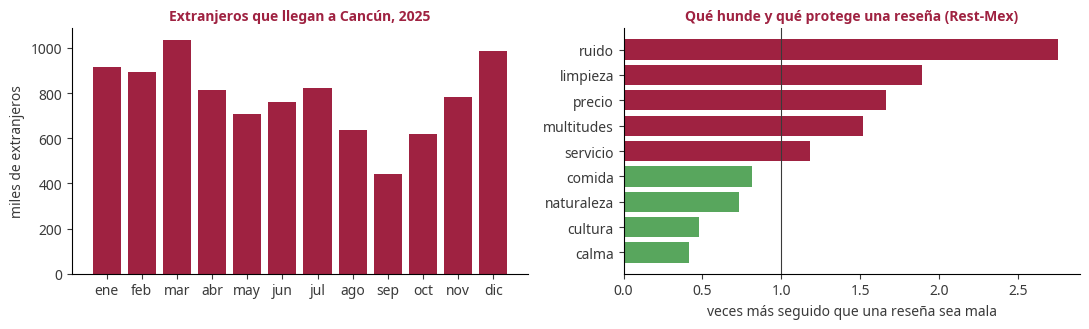

In [3]:
asp = pd.read_parquet(GOLD / "campana_aspectos.parquet")
rr = asp[asp.pueblo == "Quintana Roo (3 pueblos)"].set_index("aspecto").riesgo_relativo.sort_values()
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
ejes[0].bar(MESES, mes.reindex(range(1, 13)) / 1e3, color=GUINDA)
ejes[0].set_ylabel("miles de extranjeros"); ejes[0].set_title("Extranjeros que llegan a Cancún, 2025", fontsize=10)
ejes[1].barh(rr.index, rr, color=[PALETA[3] if x < 1 else GUINDA for x in rr])
ejes[1].axvline(1, color=GRIS, lw=0.8); ejes[1].set_xlabel("veces más seguido que una reseña sea mala")
ejes[1].set_title("Qué hunde y qué protege una reseña (Rest-Mex)", fontsize=10)
fig.tight_layout(); guardar(fig, "7_segmentacion")

## 2. Elegir: dos viajeras ideales (buyer persona)
Elegimos **dos** personas. Descartamos **solo la nacional** (deja fuera al extranjero que ya está a unos 330 km, en
Cancún) y **solo la extranjera** (la Bahía es 95 % nacional). Cada rasgo lleva su etiqueta; lo que no tiene dato oficial
no se inventa: se marca como hueco.

In [4]:
filas = []
for p in campana["personas"]:
    for rasgo, valor, tipo, fuente in p["atributos"]:
        filas.append({"persona": p["nombre"], "rasgo": rasgo, "valor": valor, "tipo": tipo.upper(), "fuente": fuente})
personas = pd.DataFrame(filas)
print(personas.groupby(["persona", "tipo"]).size().unstack(fill_value=0).to_string())
personas

tipo                   DATO  DERIVADO  HUECO  SUPUESTO
persona                                               
La que baja del norte     4         2      0         1
La que vuelve al sur      2         3      2         0


,persona,rasgo,valor,tipo,fuente
0,La que vuelve al sur,Origen,Nacional: 94.8 % de los visitantes de Oxtankah y 63.3 % de los de la Ruta en...,DATO,INAH 2025
1,La que vuelve al sur,Estado de origen,No se publica de qué estado vienen los visitantes nacionales,HUECO,—
2,La que vuelve al sur,Cuándo viaja,Diciembre a abril (temporada alta del sur); la campaña la invita en mayo–jun...,DERIVADO,"Forma del año, Fase 5"
3,La que vuelve al sur,Qué valora,Calma y cultura: una reseña que habla de calma es mala 0.41 veces lo normal;...,DERIVADO,"Rest-Mex 2025, texto.py"
4,La que vuelve al sur,Qué la aleja,"Ruido (2.8×), suciedad (1.9×), precio (1.7×) y multitudes (1.5×) en reseñas ...",DERIVADO,Rest-Mex 2025
5,La que vuelve al sur,Cómo se informa,Mensajería (90.6 %) y redes sociales (80.4 %) en el teléfono,DATO,"ENDUTIH 2025, pág. 17"
6,La que vuelve al sur,Edad e ingreso,No hay dato oficial por destino: no se fija,HUECO,—
7,La que baja del norte,Origen,"Estados Unidos 56.3 % y Canadá 17.1 % de los 9,408,423 extranjeros que llega...",DATO,UPM vía DataTur
8,La que baja del norte,Sexo,Mujeres 53.4 %,DATO,UPM vía DataTur
9,La que baja del norte,Por qué no llega sola al sur,El aeropuerto de Chetumal recibió 250 extranjeros en 2025,DATO,UPM vía DataTur


## 3. Posicionar: la marca
- **Nombre:** "El sur tiene espacio" (*The south has room*). Dice el dato (capacidad ociosa, notebook 2) y la promesa (sin
  multitudes) a la vez.
- **Lema:** "Pirámides, bahía y sabor del sur, con espacio para disfrutarlos".
- **Llamado de la página:** "El viaje de tus sueños. Está en el sur." Lo cambiamos por sugerencia del profesor de la
  materia: el nombre de la campaña explica el dato; el llamado tiene que despertar el deseo de viajar.
- **Personalidad:** cercana y tranquila; orgullosa de lo maya y de lo mexicano; con espíritu de aventura.
- **Propuesta de valor:** el Caribe mexicano que todavía tiene espacio, con zonas mayas que reciben 15.5 veces menos
  visitantes que Tulum (INAH 2025), una bahía tranquila y la comida del sur.
- **Posicionamiento:** para quien quiere el Caribe mexicano sin multitudes, el sur de Quintana Roo es la opción cultural
  y tranquila; a diferencia de Tulum o Cancún, aquí hay espacio, y la campaña lo cuida: nunca anuncia un lugar lleno.
- **Identidad visual:** el sistema "Sur mexicano": rosa, amarillo, turquesa y añil en bloques; Bricolage Grotesque y
  Figtree; greca maya; solo fotos reales con coordenada comprobada en el municipio de cada lugar.

## 4. Los mensajes: cada promesa con su dato
Reglas: cada anuncio lleva el dato que lo respalda; no se mencionan precios ni horas de viaje (no hay dato oficial); el
lenguaje sale de las palabras de las reseñas de 5 estrellas; y el largo se revisa contra los límites de cada plataforma
(Google: título hasta 30 caracteres y descripción hasta 90; Meta: título hasta 40 y texto hasta 125).

In [5]:
LIMITES = {"google_titulo": 30, "google_descripcion": 90, "meta_titulo": 40, "meta_texto": 125}
filas = []
for m in campana["mensajes"]:
    if m["canal"].startswith("Google"):
        textos = [("título", t, LIMITES["google_titulo"]) for t in m["titulos"]] + [("descripción", m["descripcion"], LIMITES["google_descripcion"])]
    elif m["canal"].startswith("Facebook"):
        textos = [("título", m["titulo"], LIMITES["meta_titulo"]), ("texto", m["texto"], LIMITES["meta_texto"])]
    else:
        textos = [("texto", m["texto"], None)]
    for parte, t, limite in textos:
        filas.append({"persona": m["persona"], "canal": m["canal"], "idioma": m["idioma"], "parte": parte, "texto": t,
                      "caracteres": len(t), "límite": limite, "cabe": limite is None or len(t) <= limite})
msj = pd.DataFrame(filas)
assert msj.cabe.all(), "un anuncio se pasa del límite de su plataforma"
print(f"✓ {len(msj)} textos dentro del límite de su plataforma")
print(pd.DataFrame(campana["mensajes"])[["persona", "canal", "respaldo"]].to_string(index=False))
msj

✓ 13 textos dentro del límite de su plataforma
persona                canal                                                                                                                                                      respaldo
 vuelve    Google (búsqueda)                                                                                         INAH 2025: Tulum 1,031,443 visitantes; Ruta 66,628 (15.5 veces menos)
 vuelve Facebook / Instagram                                                                                           Oxtankah recibió 11,017 visitantes en 2025 (INAH), 94.8 % mexicanos
 vuelve  WhatsApp (orgánico)                                                                                       90.6 % usa mensajería en el teléfono (ENDUTIH 2025, pág. 17); sin costo
   baja    Google (búsqueda)                                           INAH 2025: Tulum 1,031,443 visitantes; Ruta 66,628 (15.5 veces menos); Cancún en temporada alta nov–abr (planeador)
   baja Facebook /

,persona,canal,idioma,parte,texto,caracteres,límite,cabe
0,vuelve,Google (búsqueda),es,título,Pirámides mayas con espacio,27,30.0,True
1,vuelve,Google (búsqueda),es,título,"Kohunlich, Dzibanché, Ichkabal",30,30.0,True
2,vuelve,Google (búsqueda),es,título,El sur tiene espacio,20,30.0,True
3,vuelve,Google (búsqueda),es,descripción,Recorre la selva y las ruinas del sur sin multitudes. Planea tu viaje con ca...,80,90.0,True
4,vuelve,Facebook / Instagram,es,título,La bahía que te esperaba,24,40.0,True
5,vuelve,Facebook / Instagram,es,texto,"Mariscos frente al mar, una ciudad maya en la orilla y una tarde tranquila. ...",91,125.0,True
6,vuelve,WhatsApp (orgánico),es,texto,"¿Y si este puente nos vamos al sur? Chetumal, la bahía y las pirámides, con ...",99,NaN,True
7,baja,Google (búsqueda),en,título,"Mayan pyramids, with room",25,30.0,True
8,baja,Google (búsqueda),en,título,The south has room,18,30.0,True
9,baja,Google (búsqueda),en,título,Take the Tren Maya south,24,30.0,True


## 5. Los medios y el embudo esperado
El reparto entre canales sale del modelo de Investigación de Operaciones (notebook 6): Facebook/Instagram rinde 6.61
visitantes por cada $1,000 y Google 1.59, y el tope de 70 % por canal deja 70/30. WhatsApp (compartir) no cuesta: 90.6 %
usa mensajería. Todos los anuncios llevan a la página, que es el destino de la campaña.

**El embudo se recorre al revés de como se paga:** con el dinero se compran clics; para conseguir esos clics, cierta
cantidad de personas tuvo que ver el anuncio; y de los clics, una parte se convierte en visitantes.

$$\text{clics} = \frac{\text{pesos}}{\text{costo por clic}}, \qquad \text{impresiones} = \frac{\text{clics}}{\text{CTR}}, \qquad
\text{visitantes} = \text{clics} \times \text{conversión}$$

In [6]:
bm = pd.read_csv(sorted((RAIZ / "datos" / "bronze" / "benchmarks").glob("*/benchmarks_tablas.csv"))[-1])
t = bm[bm.categoria == "Travel"].set_index(["clave_pagina", "metrica"]).valor
fx = pd.read_parquet(SILVER / "fred_mensual")
TC = float(fx[~fx.mes_incompleto_flag & fx.pesos_por_dolar.notna()].sort_values("periodo").pesos_por_dolar.iloc[-1])
plan = pd.read_parquet(GOLD / "presupuesto_plan.parquet").groupby("canal").pesos.sum()
canales = {"Facebook": ("wordstream_facebook_2025", float(t["wordstream_google_2025", "Average CVR"]) / 100),   # conversión supuesta = la de Google
           "Google": ("wordstream_google_2025", float(t["wordstream_google_2025", "Average CVR"]) / 100)}
filas = []
for canal, (pagina, cvr) in canales.items():
    cpc = float(t[pagina, "Average CPC"]) * TC                                 # costo por clic en pesos
    ctr = float(t[pagina, "Average CTR"]) / 100                                # tasa de clics
    clics = plan[canal] / cpc
    filas.append({"canal": canal, "pesos": plan[canal], "costo por clic (MXN)": cpc, "clics": clics, "CTR": ctr,
                  "impresiones": clics / ctr, "conversión": cvr, "visitantes": clics * cvr})
embudo = pd.DataFrame(filas).set_index("canal")
embudo.loc["Total"] = embudo.sum(numeric_only=True)
embudo.loc["Total", ["costo por clic (MXN)", "CTR", "conversión"]] = np.nan
cpa = embudo.loc["Total", "pesos"] / embudo.loc["Total", "visitantes"]
sens = pd.read_parquet(GOLD / "presupuesto_sensibilidad.parquet").query("caso == 'Base'").iloc[0]
coincide("visitantes del embudo = los del modelo de presupuesto", embudo.loc["Total", "visitantes"], sens.visitantes_esperados, tolerancia=1e-6)
print(f"Costo por visitante: ${cpa:,.0f}")
embudo.round(3)

✓ visitantes del embudo = los del modelo de presupuesto: coincide con el proyecto (diferencia máxima 3.2e-07)
Costo por visitante: $196


,pesos,costo por clic (MXN),clics,CTR,impresiones,conversión,visitantes
canal,,,,,,,
Facebook,131250.000,8.701,15084.388,0.028,546535.784,0.058,867.352
Google,56249.935,36.169,1555.195,0.087,17814.370,0.058,89.424
Total,187499.936,NaN,16639.582,NaN,564350.154,NaN,956.776


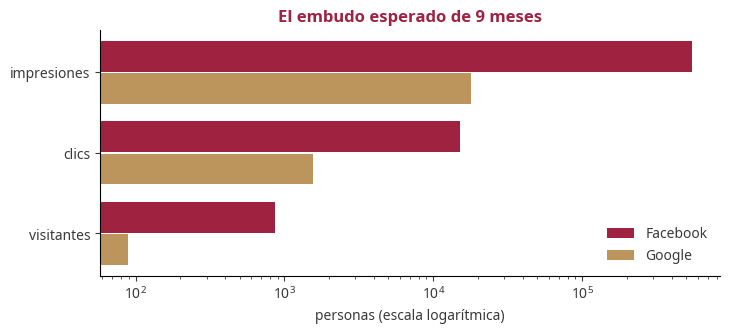

In [7]:
x = embudo.drop(index="Total")
fig, ax = plt.subplots(figsize=(8, 3.2))
etapas = ["impresiones", "clics", "visitantes"]
for j, (canal, color) in enumerate(zip(x.index, [GUINDA, DORADO])):
    ax.barh(np.arange(3) + 0.4 * j, x.loc[canal, etapas], 0.38, color=color, label=canal)
ax.set_yticks(np.arange(3) + 0.2, etapas); ax.set_xscale("log"); ax.invert_yaxis()
ax.set_xlabel("personas (escala logarítmica)"); ax.legend(frameon=False); ax.set_title("El embudo esperado de 9 meses")
guardar(fig, "7_embudo")

Son **estimaciones con promedios de anunciantes de Estados Unidos** (WordStream 2025): las metas reales se
fijan con el primer mes de campaña. El total coincide con los 956.8 visitantes del modelo de presupuesto, que es el
mismo cálculo visto por canal.

## 6. Indicadores (KPI)
Medimos lo de mercadotecnia (alcance, interacción, conversión, costo) **y** el impacto que pide el Problema Prototípico
(afluencia, efectos económicos, sociales y ambientales). Uno de ellos es un hueco declarado: no hay ocupación hotelera
oficial del sur desde 2025.

In [8]:
pd.DataFrame(campana["kpis"])

,kpi,formula,meta,fuente,frecuencia
0,Alcance,Personas únicas que vieron un anuncio,Se fija con el primer mes real (no hay dato previo),Plataformas,Semanal
1,Interacción (CTR),Clics ÷ impresiones,Google ≥ 8.73 %; Facebook ≥ 2.76 % (promedios de Travel),Plataformas; WordStream 2025,Semanal
2,Conversión,Planes de viaje o contactos ÷ clics,≥ 5.75 % (Google Travel),Página web,Semanal
3,Costo por visitante,Pesos gastados ÷ conversiones,≤ $196 (modelo de la Fase 6),Plataformas + página,Mensual
4,Afluencia,Visitantes reales − escenario probable del pronóstico,"+957 en 9 meses, sin pasar la capacidad probada","INAH, SITUR-Q (Belice)",Mensual
5,Presupuesto,Pesos gastados ÷ pesos planeados,100 % (lo pausado se gasta después),Torre en vivo,Semanal
6,Económico,Ocupación hotelera de Chetumal,Hueco: SITUR-Q no publica ocupación del sur desde 2025,—,—
7,Social,"Visitantes por cada 1,000 habitantes (Radar)","El lugar sigue ""tranquilo"" o ""concurrido"", nunca ""saturado""","Radar, Fase 4",Mensual
8,Ambiental,Semanas con anuncio en temporada alta o con mal clima,0 (la Torre las pausa),"Torre en vivo, Fase 7",Semanal
9,Capacidad,(Esperados + campaña) ÷ capacidad probada,"≤ 40 % en los meses con anuncio (Pareto, Fase 6)",Pronóstico + presupuesto,Mensual


## 7. La regla anti-colapso
El incidente crítico pregunta qué hacer si la afluencia rebasa la capacidad. La campaña tiene la respuesta
**programada**, no solo escrita:

1. Nunca anuncia un lugar en su temporada alta (restricción R2 del presupuesto, notebook 6).
2. No permite que los visitantes esperados más los de la campaña pasen de la capacidad probada (R3), y la frontera de
   Pareto muestra que ningún mes con anuncio necesita pasar de 40 % de su capacidad.
3. La Torre pausa el anuncio la semana en que hay tormenta, clima raro o llegó más gente de la esperada (notebook 6).
4. A quien iba al norte lleno le ofrece el lugar del sur con más espacio, nunca otro lugar lleno ("¿Ibas al norte?").

Lo comprobamos con la reproducción de las 239 semanas reales:

In [9]:
dec = pd.read_parquet(GOLD / "envivo_decisiones.parquet")
norte = pd.read_parquet(GOLD / "envivo_norte.parquet")
gasto_alta = dec[dec.accion == "temporada alta"].pesos_gastados.sum()
print(f"Pesos gastados en semanas de temporada alta: ${gasto_alta:,.0f}")
print(f"Semanas pausadas por tormenta, clima raro o llegadas altas: {(dec.accion == 'pausado').sum()} (lugar-semana)")
print(f"Semanas con '¿Ibas al norte?': {int(norte.ibas_al_norte.sum())} → destinos:", norte[norte.ibas_al_norte].destino.value_counts().to_dict())
encendido = set(zip(dec[dec.accion == "encendido"].semana, dec[dec.accion == "encendido"].lugar))
destinos_ok = all((r.semana, r.destino) in encendido for r in norte[norte.ibas_al_norte].itertuples())   # el destino estaba encendido esa semana
assert gasto_alta == 0 and destinos_ok, "la regla anti-colapso no se cumplió"
print("✓ nunca se gastó en temporada alta y la Torre solo mandó gente a lugares del sur encendidos")

Pesos gastados en semanas de temporada alta: $0
Semanas pausadas por tormenta, clima raro o llegadas altas: 48 (lugar-semana)
Semanas con '¿Ibas al norte?': 6 → destinos: {'Bahía Calderitas–Oxtankah': 6}
✓ nunca se gastó en temporada alta y la Torre solo mandó gente a lugares del sur encendidos


## 8. La integración: la estafeta
La salida de cada materia es la entrada de la siguiente. Nada de la campaña se decide sin un número de las otras cinco.

| Materia (notebook) | Entrega | La usa |
|---|---|---|
| Grandes volúmenes (1) | Bronze → Silver → Gold trazable; streaming semanal | Todas |
| Planteamiento (2) | La concentración medida (HHI) y los 5 lugares | La campaña: a quién y dónde |
| Minería (3) | El índice de presión, la forma del año, el clima raro, lo que molesta en las reseñas | El clasificador, el calendario, la Torre, los mensajes |
| Aprendizaje de máquina (4) | El estado del mes siguiente y el pronóstico de 12 meses con su rango | Monte Carlo, calendario, presupuesto |
| Estocásticos (5) | Probabilidad de tormenta, cadena de Markov del norte, escenarios malo/probable/bueno | Presupuesto (etapa 2), "¿Ibas al norte?" |
| Investigación de Operaciones (6) | Cuánto dinero, dónde, cuándo y por qué canal; el motor semanal | Medios, calendario y KPI de la campaña |
| Mercadotecnia (7) | Personas, marca, mensajes, medios, embudo e indicadores | La página y el coloquio |

| Decisión de la campaña | Elegimos | Por qué | Qué descartamos |
|---|---|---|---|
| Personas | Dos: la que vuelve (nacional) y la que baja del norte (extranjera en Cancún) | La Bahía es 95 % nacional; el extranjero ya está en Cancún | Solo una de las dos |
| A quién no se le compra anuncio | Al extranjero en su país | Solo 250 extranjeros llegaron por avión a Chetumal | Campañas internacionales |
| Nombre | "El sur tiene espacio" | Dice el dato y la promesa | Nombres sin respaldo de datos |
| Mensajes | Con el dato que los respalda; sin precios ni horas | No hay dato oficial de precios ni de tiempos | Prometer lo que no se puede medir |
| Medios | Facebook/Instagram 70 %, Google 30 %, WhatsApp orgánico | Rendimiento por peso y uso medido (ENDUTIH) | Medios impresos o TV (sin dato de rendimiento) |
| Metas | Promedios de viajes, se ajustan con el primer mes | Es el único dato publicado | Inventar metas para México |
| Si se llena | Regla anti-colapso programada | Responde al incidente crítico con código | Solo un aviso escrito |